# 🌲🌲🌲 Glass Identification — Random Forest

**Dataset:** [UCI Glass Identification](https://archive.ics.uci.edu/dataset/42/glass+identification)  
**Tarefa:** Classificação multiclasse (6 tipos de vidro)  
**Instâncias:** 214 | **Features:** 9 (todas contínuas) | **Valores ausentes:** Nenhum

---

### Por que Random Forest em vez de uma única Árvore de Decisão?

| Característica | Árvore de Decisão | Random Forest |
|---|---|---|
| Variância | Alta (overfitting fácil) | Baixa (média de muitas árvores) |
| Splits espúrios | Vulnerável | Mitigado pelo bagging + feature sampling |
| Interpretabilidade | Alta | Moderada (via importâncias) |
| Robustez a ruído | Baixa | Alta |
| Performance geral | Boa | Superior na maioria dos casos |

O Random Forest cria **N árvores independentes**, cada uma treinada em uma amostra bootstrap dos dados e usando um subconjunto aleatório de features em cada split. O resultado final é a **votação majoritária** entre todas as árvores.

---
### Etapas do pipeline:
1. Instalação de dependências
2. Carregamento dos dados
3. Análise exploratória (EDA)
4. Remoção do ID e verificação de duplicatas
5. Detecção e tratamento de outliers
6. Balanceamento de classes (SMOTE)
7. Engenharia de features
8. Divisão estratificada dos dados
9. Treinamento e otimização do Random Forest
10. Avaliação e visualização dos resultados
11. Comparativo: Random Forest vs. Árvore de Decisão única

## 📦 Etapa 1 — Instalação de Dependências

In [25]:
!pip install ucimlrepo imbalanced-learn --quiet

## 📥 Etapa 2 — Carregamento dos Dados

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from ucimlrepo import fetch_ucirepo

# Carrega o dataset diretamente do repositório UCI
glass_identification = fetch_ucirepo(id=42)

X = glass_identification.data.features.copy()
y = glass_identification.data.targets.copy()

# Unifica em um único DataFrame para exploração
df = pd.concat([X, y], axis=1)
df.columns = list(X.columns) + ['Type']

print('✅ Dataset carregado com sucesso!')
print(f'   Shape: {df.shape}')
print(f'   Features: {list(X.columns)}')
df.head()

✅ Dataset carregado com sucesso!
   Shape: (214, 10)
   Features: ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


## 🔎 Etapa 3 — Análise Exploratória (EDA)

In [27]:
print('=== INFORMAÇÕES GERAIS ===')
df.info()
print()
print('=== ESTATÍSTICAS DESCRITIVAS ===')
df.describe().round(4)

=== INFORMAÇÕES GERAIS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB

=== ESTATÍSTICAS DESCRITIVAS ===


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000,214.0000
mean,1.5184,13.4079,2.6845,1.4449,72.6509,0.4971,8.9570,0.1750,0.0570,2.7804
std,0.0030,0.8166,1.4424,0.4993,0.7745,0.6522,1.4232,0.4972,0.0974,2.1037
min,1.5112,10.7300,0.0000,0.2900,69.8100,0.0000,5.4300,0.0000,0.0000,1.0000
25%,1.5165,12.9075,2.1150,1.1900,72.2800,0.1225,8.2400,0.0000,0.0000,1.0000
50%,1.5177,13.3000,3.4800,1.3600,72.7900,0.5550,8.6000,0.0000,0.0000,2.0000
75%,1.5192,13.8250,3.6000,1.6300,73.0875,0.6100,9.1725,0.0000,0.1000,3.0000
max,1.5339,17.3800,4.4900,3.5000,75.4100,6.2100,16.1900,3.1500,0.5100,7.0000


In [28]:
print('=== VALORES AUSENTES ===')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else '✅ Nenhum valor ausente encontrado.')

=== VALORES AUSENTES ===
✅ Nenhum valor ausente encontrado.


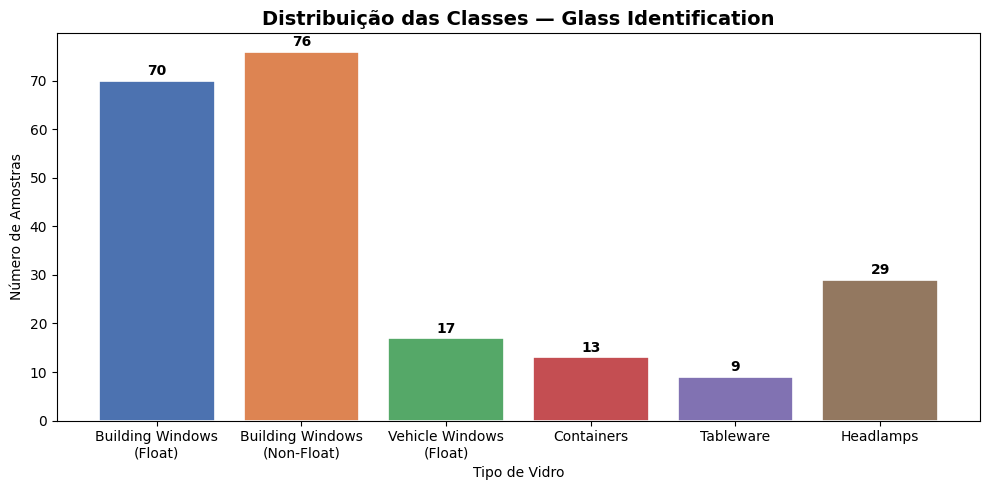


⚠️  Dataset fortemente desbalanceado:
   Classe 1 (Building Windows
(Float)): 70 amostras (32.7%)
   Classe 2 (Building Windows
(Non-Float)): 76 amostras (35.5%)
   Classe 3 (Vehicle Windows
(Float)): 17 amostras (7.9%)
   Classe 5 (Containers): 13 amostras (6.1%)
   Classe 6 (Tableware): 9 amostras (4.2%)
   Classe 7 (Headlamps): 29 amostras (13.6%)


In [29]:
nomes_classes = {
    1: 'Building Windows\n(Float)',
    2: 'Building Windows\n(Non-Float)',
    3: 'Vehicle Windows\n(Float)',
    5: 'Containers',
    6: 'Tableware',
    7: 'Headlamps'
}

contagem = df['Type'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    [nomes_classes.get(i, str(i)) for i in contagem.index],
    contagem.values,
    color=['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860'],
    edgecolor='white', linewidth=1.2
)
for bar, val in zip(bars, contagem.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            str(val), ha='center', va='bottom', fontweight='bold')

ax.set_title('Distribuição das Classes — Glass Identification', fontsize=14, fontweight='bold')
ax.set_ylabel('Número de Amostras')
ax.set_xlabel('Tipo de Vidro')
plt.tight_layout()
plt.show()

print('\n⚠️  Dataset fortemente desbalanceado:')
for cls, cnt in contagem.items():
    print(f'   Classe {cls} ({nomes_classes.get(cls,"?")}): {cnt} amostras ({cnt/len(df)*100:.1f}%)')

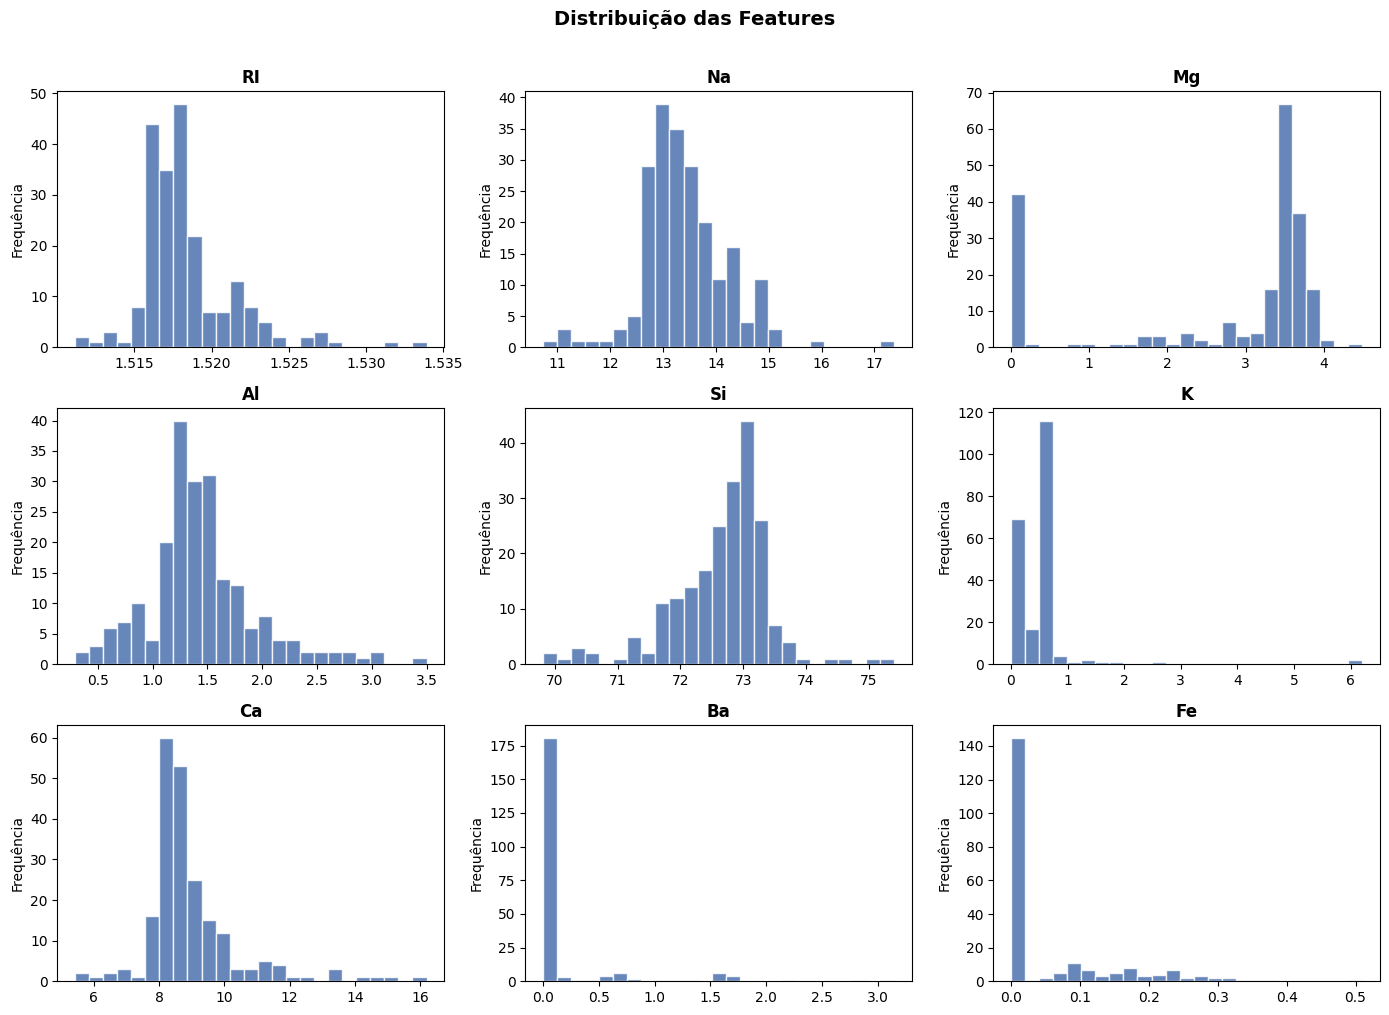

In [30]:
features = list(X.columns)

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(features):
    axes[i].hist(df[feat], bins=25, color='#4C72B0', edgecolor='white', alpha=0.85)
    axes[i].set_title(feat, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Frequência')

plt.suptitle('Distribuição das Features', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

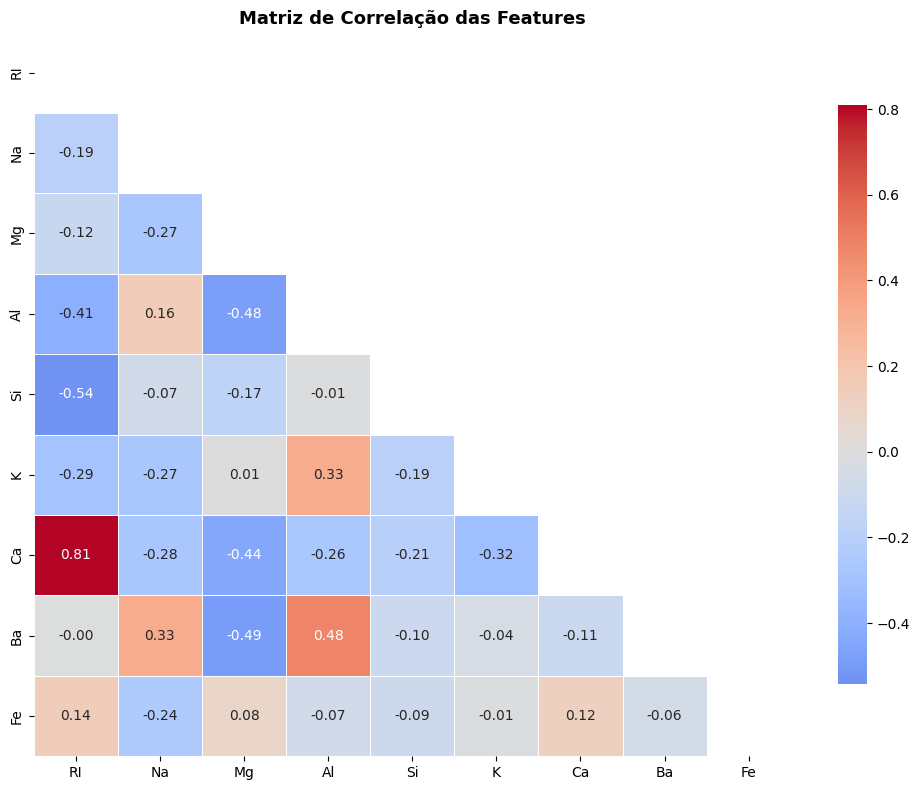


=== PARES COM CORRELAÇÃO ALTA (|r| > 0.5) ===
   Si × RI: -0.542
   Ca × RI: 0.810

💡 Nota para Random Forest: correlação entre features é MENOS problemática do que
   em modelos lineares. O sorteio aleatório de features por split reduz naturalmente
   o impacto de features correlacionadas ao distribuí-las entre árvores diferentes.


In [31]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Matriz de Correlação das Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('\n=== PARES COM CORRELAÇÃO ALTA (|r| > 0.5) ===')
for i in range(len(corr.columns)):
    for j in range(i):
        val = corr.iloc[i, j]
        if abs(val) > 0.5:
            print(f'   {corr.columns[i]} × {corr.columns[j]}: {val:.3f}')

print('\n💡 Nota para Random Forest: correlação entre features é MENOS problemática do que')
print('   em modelos lineares. O sorteio aleatório de features por split reduz naturalmente')
print('   o impacto de features correlacionadas ao distribuí-las entre árvores diferentes.')

## 🗑️ Etapa 4 — Remoção do ID e Duplicatas

In [32]:
cols_id = [c for c in df.columns if 'id' in c.lower() or 'Id' in c]
if cols_id:
    df.drop(columns=cols_id, inplace=True)
    print(f'✅ Colunas de ID removidas: {cols_id}')
else:
    print('✅ Nenhuma coluna de ID presente nas features.')

n_antes = len(df)
df.drop_duplicates(inplace=True)
n_depois = len(df)
print(f'✅ Duplicatas removidas: {n_antes - n_depois} | Registros restantes: {n_depois}')

X = df.drop(columns=['Type'])
y = df['Type']

✅ Nenhuma coluna de ID presente nas features.
✅ Duplicatas removidas: 1 | Registros restantes: 213


## 📊 Etapa 5 — Detecção e Tratamento de Outliers

> **Random Forest é mais robusto a outliers** do que uma única árvore, pois o bagging (amostragem com reposição) reduz a influência de pontos anômalos — cada árvore pode ou não incluir o outlier em sua amostra bootstrap. Ainda assim, outliers extremos em `Ba` e `Fe` podem distorcer algumas árvores individuais.

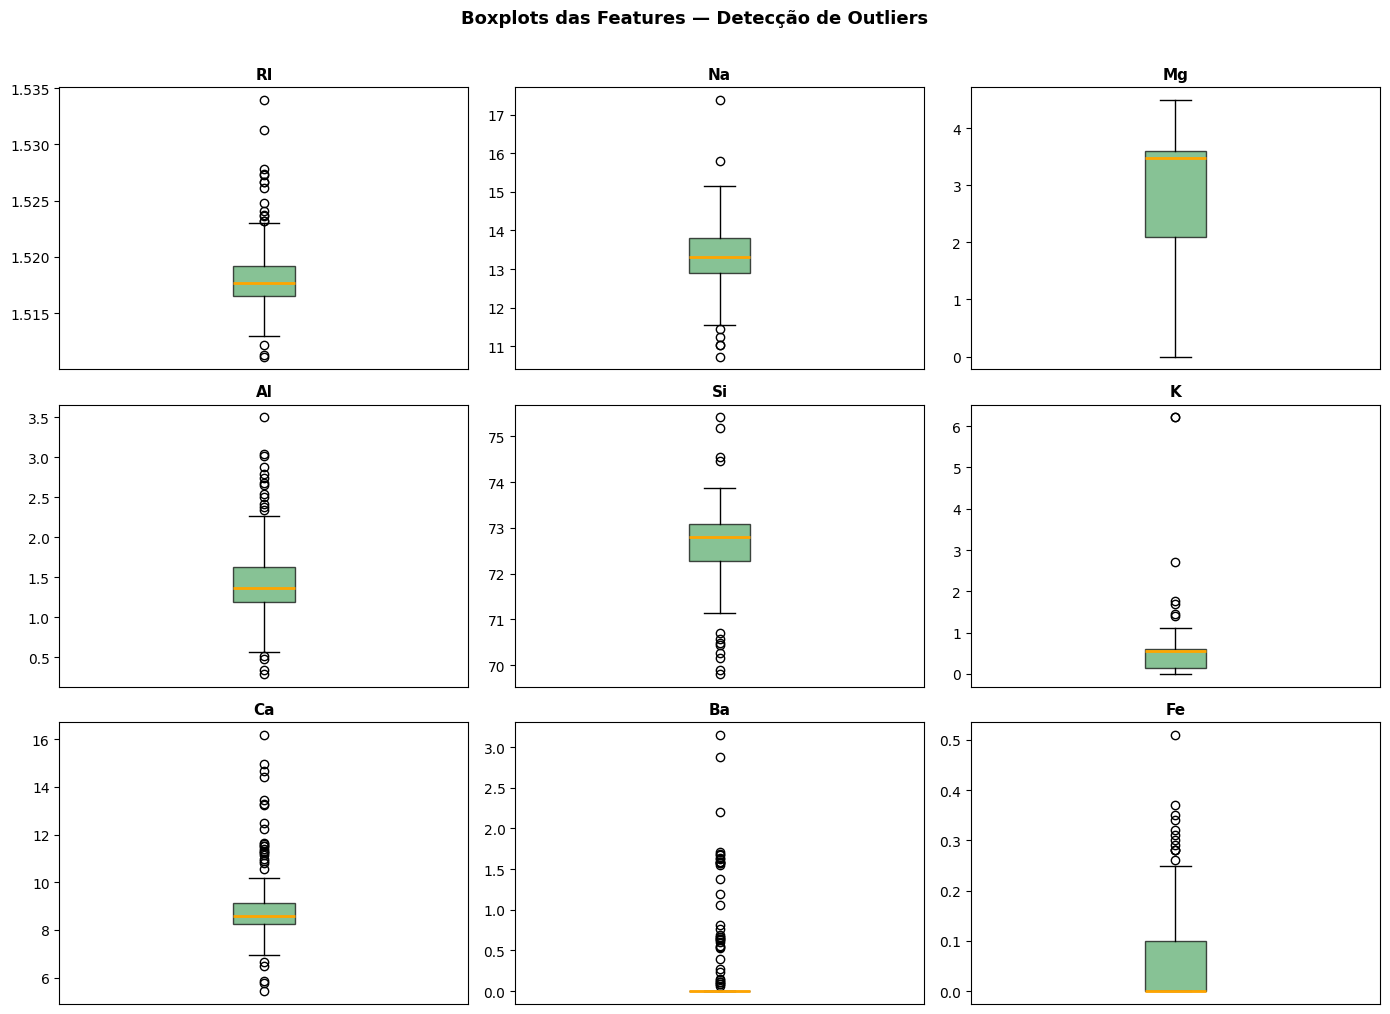

In [33]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, feat in enumerate(X.columns):
    axes[i].boxplot(X[feat], patch_artist=True,
                    boxprops=dict(facecolor='#55A868', alpha=0.7),
                    medianprops=dict(color='orange', linewidth=2))
    axes[i].set_title(feat, fontsize=11, fontweight='bold')
    axes[i].set_xticks([])

plt.suptitle('Boxplots das Features — Detecção de Outliers', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [34]:
from scipy import stats

THRESHOLD = 3.5

z_scores = np.abs(stats.zscore(X))
outlier_mask = (z_scores < THRESHOLD).all(axis=1)

n_outliers = (~outlier_mask).sum()
print(f'=== REMOÇÃO DE OUTLIERS (Z-score > {THRESHOLD}) ===')
print(f'   Outliers detectados: {n_outliers}')
print(f'   Amostras antes: {len(X)}')

X_clean = X[outlier_mask].reset_index(drop=True)
y_clean = y[outlier_mask].reset_index(drop=True)

print(f'   Amostras após remoção: {len(X_clean)}')
print(f'\n💡 Threshold 3.5 (conservador) para preservar amostras das classes minoritárias.')

=== REMOÇÃO DE OUTLIERS (Z-score > 3.5) ===
   Outliers detectados: 11
   Amostras antes: 213
   Amostras após remoção: 202

💡 Threshold 3.5 (conservador) para preservar amostras das classes minoritárias.


## ⚖️ Etapa 6 — Balanceamento de Classes com SMOTE

=== DISTRIBUIÇÃO ANTES DO SMOTE ===
Type
1    69
2    71
3    17
5     9
6     8
7    28
Name: count, dtype: int64

=== DISTRIBUIÇÃO APÓS SMOTE ===
Type
1    71
2    71
3    71
5    71
6    71
7    71
Name: count, dtype: int64

✅ Total de amostras: 426 (era 202)


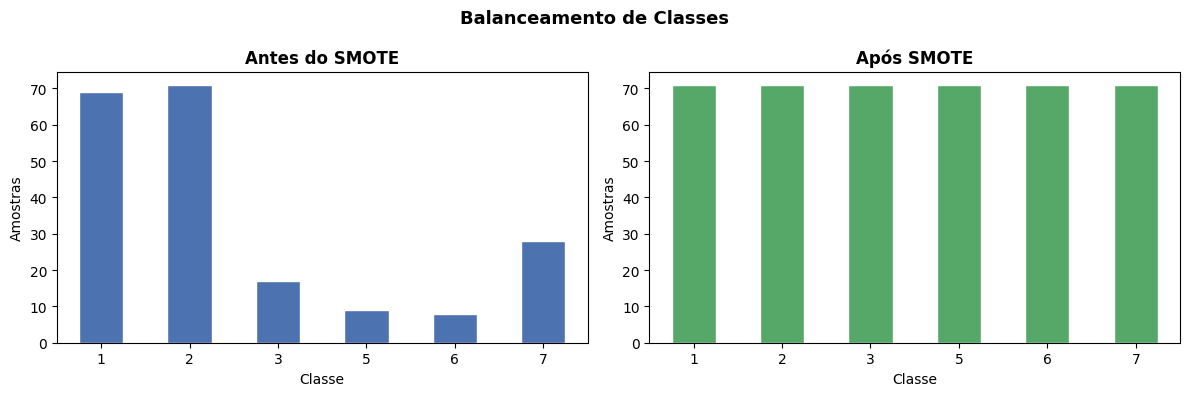

In [35]:
from imblearn.over_sampling import SMOTE

print('=== DISTRIBUIÇÃO ANTES DO SMOTE ===')
print(y_clean.value_counts().sort_index())

smote = SMOTE(random_state=42, k_neighbors=3)
X_res, y_res = smote.fit_resample(X_clean, y_clean)

print(f'\n=== DISTRIBUIÇÃO APÓS SMOTE ===')
print(pd.Series(y_res).value_counts().sort_index())
print(f'\n✅ Total de amostras: {len(X_res)} (era {len(X_clean)})')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

y_clean.value_counts().sort_index().plot(kind='bar', ax=ax1, color='#4C72B0', edgecolor='white')
ax1.set_title('Antes do SMOTE', fontweight='bold')
ax1.set_xlabel('Classe'); ax1.set_ylabel('Amostras')
ax1.tick_params(axis='x', rotation=0)

pd.Series(y_res).value_counts().sort_index().plot(kind='bar', ax=ax2, color='#55A868', edgecolor='white')
ax2.set_title('Após SMOTE', fontweight='bold')
ax2.set_xlabel('Classe'); ax2.set_ylabel('Amostras')
ax2.tick_params(axis='x', rotation=0)

plt.suptitle('Balanceamento de Classes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 🛠️ Etapa 7 — Engenharia de Features

In [36]:
X_eng = pd.DataFrame(X_res, columns=X_clean.columns)

# Features binárias para atributos esparsos
X_eng['Ba_presente'] = (X_eng['Ba'] > 0).astype(int)
X_eng['Fe_presente'] = (X_eng['Fe'] > 0).astype(int)

# Razões entre óxidos com significado químico
X_eng['Na_Ca_ratio'] = X_eng['Na'] / (X_eng['Ca'] + 1e-5)
X_eng['Si_Al_ratio'] = X_eng['Si'] / (X_eng['Al'] + 1e-5)
X_eng['Mg_Al_ratio'] = X_eng['Mg'] / (X_eng['Al'] + 1e-5)

print('=== FEATURES APÓS ENGENHARIA ===')
print(f'   Features originais:       {len(X_clean.columns)}')
print(f'   Features após engenharia: {len(X_eng.columns)}')
print(f'   Novas features: {[c for c in X_eng.columns if c not in X_clean.columns]}')
print()
print('💡 Para o Random Forest, features extras ajudam mais do que atrapalham:')
print('   o sorteio aleatório por split descarta features irrelevantes naturalmente.')
X_eng.head(3)

=== FEATURES APÓS ENGENHARIA ===
   Features originais:       9
   Features após engenharia: 14
   Novas features: ['Ba_presente', 'Fe_presente', 'Na_Ca_ratio', 'Si_Al_ratio', 'Mg_Al_ratio']

💡 Para o Random Forest, features extras ajudam mais do que atrapalham:
   o sorteio aleatório por split descarta features irrelevantes naturalmente.


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Ba_presente,Fe_presente,Na_Ca_ratio,Si_Al_ratio,Mg_Al_ratio
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,0,0,1.558855,65.253952,4.081781
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,0,0,1.773944,53.477548,2.647039
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,0,0,1.739072,47.395796,2.305180


## ✂️ Etapa 8 — Divisão Estratificada dos Dados

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_eng,
    y_res,
    test_size=0.2,
    random_state=42,
    stratify=y_res
)

print('=== DIVISÃO DOS DADOS ===')
print(f'   Treino:   {X_train.shape[0]} amostras ({X_train.shape[0]/len(X_eng)*100:.1f}%)')
print(f'   Teste:    {X_test.shape[0]} amostras ({X_test.shape[0]/len(X_eng)*100:.1f}%)')
print(f'   Features: {X_train.shape[1]}')
print()
print('Distribuição de classes no treino:')
print(pd.Series(y_train).value_counts().sort_index())
print('\nDistribuição de classes no teste:')
print(pd.Series(y_test).value_counts().sort_index())

=== DIVISÃO DOS DADOS ===
   Treino:   340 amostras (79.8%)
   Teste:    86 amostras (20.2%)
   Features: 14

Distribuição de classes no treino:
Type
1    57
2    57
3    57
5    56
6    56
7    57
Name: count, dtype: int64

Distribuição de classes no teste:
Type
1    14
2    14
3    14
5    15
6    15
7    14
Name: count, dtype: int64


## 🌲 Etapa 9 — Treinamento e Otimização do Random Forest

### Hiperparâmetros exclusivos do Random Forest

| Parâmetro | Descrição | Impacto |
|---|---|---|
| `n_estimators` | Número de árvores na floresta | Mais árvores → menor variância, porém maior custo |
| `max_features` | Features sorteadas por split | Controla diversidade entre árvores |
| `max_samples` | Fração de amostras por bootstrap | Controla correlação entre árvores |
| `max_depth` | Profundidade máxima de cada árvore | Controla complexidade individual |
| `min_samples_leaf` | Mínimo de amostras por folha | Regularização contra overfitting |
| `bootstrap` | Amostragem com reposição | Reduz variância via bagging |

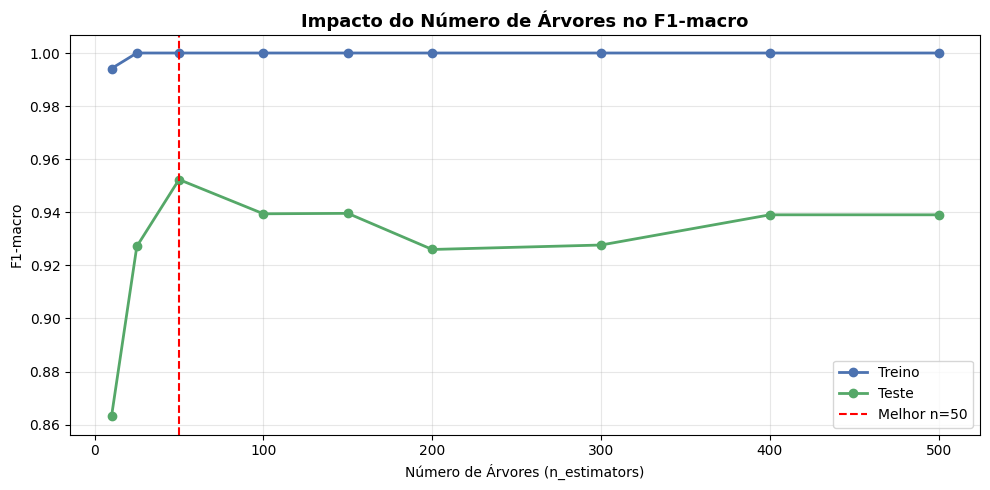


✅ Melhor n_estimators identificado: 50
   Valores acima tendem a estabilizar o desempenho (lei dos rendimentos decrescentes).


In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# Análise prévia: número ideal de árvores (n_estimators)
# Evita buscar em grade um parâmetro com comportamento monótono
n_list = [10, 25, 50, 100, 150, 200, 300, 400, 500]
f1_treino, f1_teste = [], []

for n in n_list:
    rf = RandomForestClassifier(
        n_estimators=n,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    f1_treino.append(f1_score(y_train, rf.predict(X_train), average='macro'))
    f1_teste.append(f1_score(y_test, rf.predict(X_test), average='macro'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_list, f1_treino, 'o-', label='Treino', color='#4C72B0', linewidth=2)
ax.plot(n_list, f1_teste,  'o-', label='Teste',  color='#55A868', linewidth=2)

melhor_n = n_list[np.argmax(f1_teste)]
ax.axvline(x=melhor_n, color='red', linestyle='--', label=f'Melhor n={melhor_n}')
ax.set_xlabel('Número de Árvores (n_estimators)')
ax.set_ylabel('F1-macro')
ax.set_title('Impacto do Número de Árvores no F1-macro', fontsize=13, fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'\n✅ Melhor n_estimators identificado: {melhor_n}')
print('   Valores acima tendem a estabilizar o desempenho (lei dos rendimentos decrescentes).')

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'n_estimators':      [100, 200, 300],
    'max_depth':         [None, 10, 20, 30],
    'max_features':      ['sqrt', 'log2', None],
    'min_samples_split': [2, 5],
    'min_samples_leaf':  [1, 2, 4],
    'bootstrap':         [True, False]
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print('\n=== MELHORES HIPERPARÂMETROS ===')
for param, val in grid_search.best_params_.items():
    print(f'   {param}: {val}')
print(f'\n   F1-macro (validação cruzada): {grid_search.best_score_:.4f}')

best_rf = grid_search.best_estimator_

Fitting 10 folds for each of 432 candidates, totalling 4320 fits

=== MELHORES HIPERPARÂMETROS ===
   bootstrap: True
   max_depth: None
   max_features: sqrt
   min_samples_leaf: 1
   min_samples_split: 5
   n_estimators: 100

   F1-macro (validação cruzada): 0.8969


## 📈 Etapa 10 — Avaliação e Visualização dos Resultados

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score
)

y_pred = best_rf.predict(X_test)

nomes = {
    1: 'Build.Win.Float',
    2: 'Build.Win.NonFloat',
    3: 'Veh.Win.Float',
    5: 'Containers',
    6: 'Tableware',
    7: 'Headlamps'
}
classes = sorted(pd.Series(y_test).unique())
labels  = [nomes.get(c, str(c)) for c in classes]

print('=== MÉTRICAS DE AVALIAÇÃO — RANDOM FOREST ===')
print(f'   Acurácia:    {accuracy_score(y_test, y_pred):.4f}')
print(f'   F1-macro:    {f1_score(y_test, y_pred, average="macro"):.4f}')
print(f'   F1-weighted: {f1_score(y_test, y_pred, average="weighted"):.4f}')
print()
print('=== RELATÓRIO POR CLASSE ===')
print(classification_report(y_test, y_pred, target_names=labels))

=== MÉTRICAS DE AVALIAÇÃO — RANDOM FOREST ===
   Acurácia:    0.9419
   F1-macro:    0.9400
   F1-weighted: 0.9414

=== RELATÓRIO POR CLASSE ===
                    precision    recall  f1-score   support

   Build.Win.Float       0.86      0.86      0.86        14
Build.Win.NonFloat       0.92      0.86      0.89        14
     Veh.Win.Float       0.93      0.93      0.93        14
        Containers       1.00      1.00      1.00        15
         Tableware       1.00      1.00      1.00        15
         Headlamps       0.93      1.00      0.97        14

          accuracy                           0.94        86
         macro avg       0.94      0.94      0.94        86
      weighted avg       0.94      0.94      0.94        86



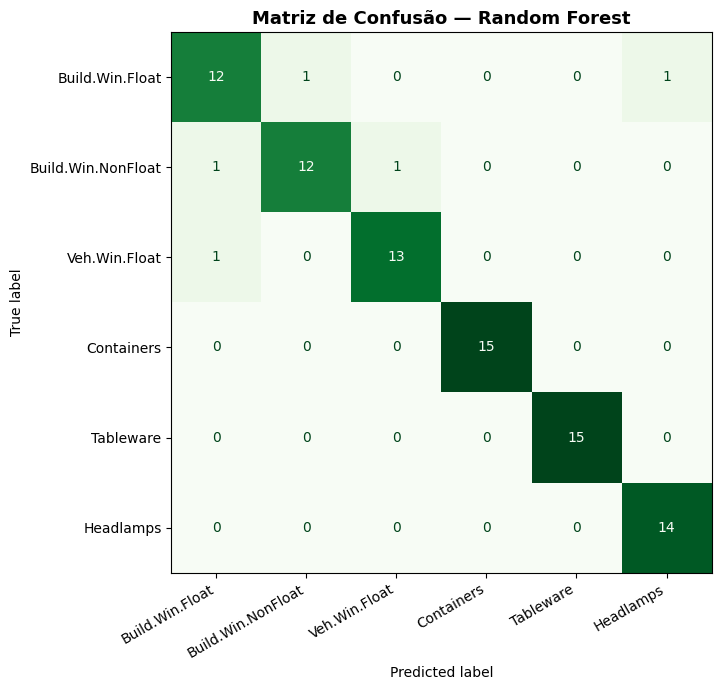

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
cm = confusion_matrix(y_test, y_pred, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title('Matriz de Confusão — Random Forest', fontsize=13, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

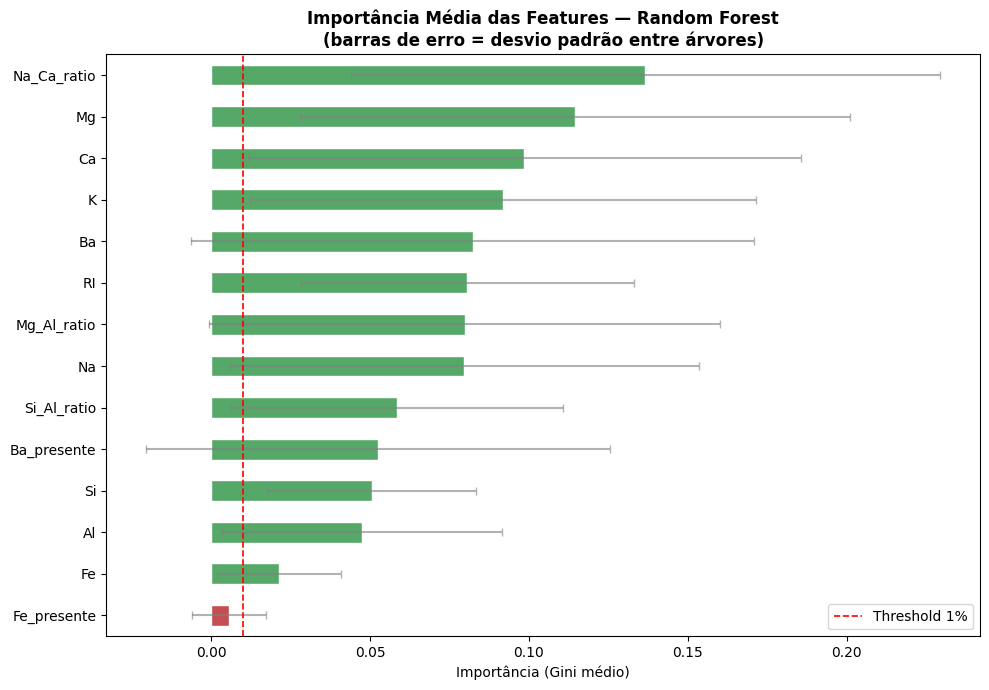


💡 As barras de erro mostram a variância da importância entre as árvores individuais.
   Features com barras longas são usadas de forma inconsistente entre as árvores.

=== RANKING COMPLETO ===
   Na_Ca_ratio        0.1367 ± 0.0928
   Mg                 0.1145 ± 0.0866
   Ca                 0.0986 ± 0.0869
   K                  0.0920 ± 0.0796
   Ba                 0.0823 ± 0.0886
   RI                 0.0806 ± 0.0524
   Mg_Al_ratio        0.0798 ± 0.0805
   Na                 0.0797 ± 0.0739
   Si_Al_ratio        0.0585 ± 0.0521
   Ba_presente        0.0524 ± 0.0730
   Si                 0.0505 ± 0.0330
   Al                 0.0476 ± 0.0440
   Fe                 0.0213 ± 0.0194
   Fe_presente        0.0057 ± 0.0117


In [ ]:
# Importância média das features (média sobre todas as árvores)
importances = best_rf.feature_importances_
std_imp     = np.std([tree.feature_importances_ for tree in best_rf.estimators_], axis=0)

feat_imp = pd.Series(importances, index=X_eng.columns)
feat_std = pd.Series(std_imp,     index=X_eng.columns)
feat_imp_sorted = feat_imp.sort_values(ascending=True)
feat_std_sorted = feat_std[feat_imp_sorted.index]

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#C44E52' if v < 0.01 else '#55A868' for v in feat_imp_sorted.values]
feat_imp_sorted.plot(
    kind='barh', ax=ax, color=colors, edgecolor='white',
    xerr=feat_std_sorted.values, capsize=3, error_kw={'ecolor': 'gray', 'alpha': 0.6}
)
ax.axvline(x=0.01, color='red', linestyle='--', linewidth=1.2,
           label='Threshold 1%')
ax.set_title('Importância Média das Features — Random Forest\n(barras de erro = desvio padrão entre árvores)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Importância (Gini médio)')
ax.legend()
plt.tight_layout()
plt.show()

print('\n💡 As barras de erro mostram a variância da importância entre as árvores individuais.')
print('   Features com barras longas são usadas de forma inconsistente entre as árvores.')

print('\n=== RANKING COMPLETO ===')
for feat, imp, std in zip(
    feat_imp.sort_values(ascending=False).index,
    feat_imp.sort_values(ascending=False).values,
    feat_std[feat_imp.sort_values(ascending=False).index].values
):
    print(f'   {feat:<18} {imp:.4f} ± {std:.4f}')

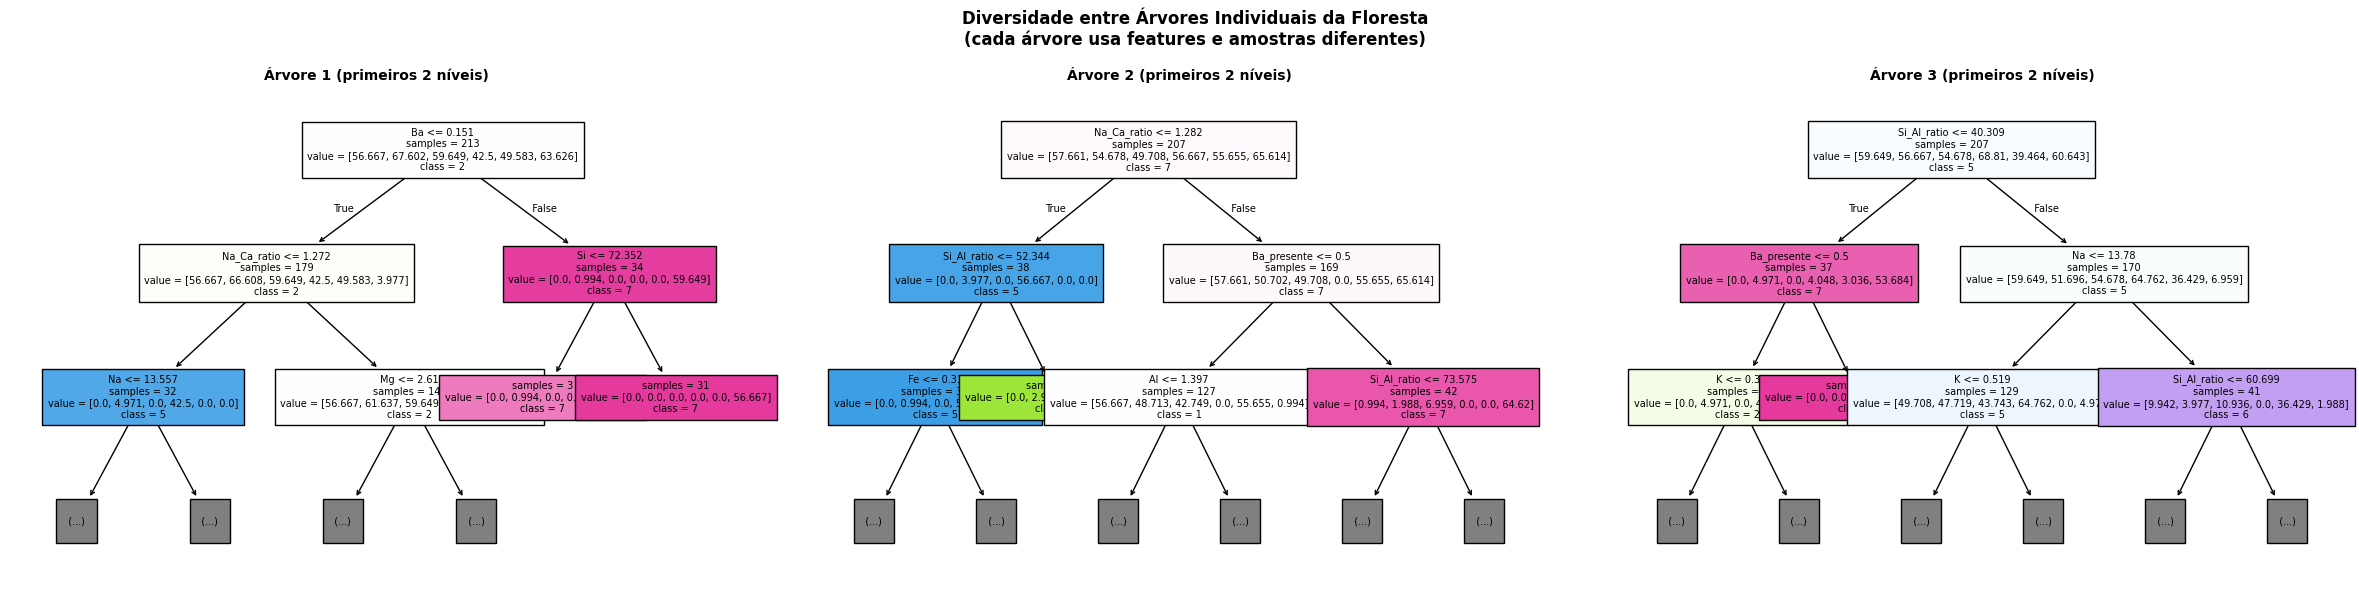


💡 Repare que as 3 árvores fazem splits em features DIFERENTES.
   É essa diversidade que torna o Random Forest robusto.


In [ ]:
from sklearn.tree import plot_tree

# Visualiza 3 árvores individuais da floresta para ilustrar a diversidade
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
indices = [0, 1, 2]

for ax, idx in zip(axes, indices):
    plot_tree(
        best_rf.estimators_[idx],
        feature_names=list(X_eng.columns),
        class_names=[str(c) for c in sorted(pd.Series(y_train).unique())],
        filled=True,
        max_depth=2,
        fontsize=7,
        ax=ax,
        impurity=False
    )
    ax.set_title(f'Árvore {idx+1} (primeiros 2 níveis)', fontweight='bold', fontsize=10)

plt.suptitle(
    'Diversidade entre Árvores Individuais da Floresta\n'
    '(cada árvore usa features e amostras diferentes)',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

print('\n💡 Repare que as 3 árvores fazem splits em features DIFERENTES.')
print('   É essa diversidade que torna o Random Forest robusto.')

In [ ]:
# Out-of-Bag Score (estimativa de generalização sem usar o conjunto de teste)
# Disponível apenas quando bootstrap=True
if grid_search.best_params_['bootstrap']:
    rf_oob = RandomForestClassifier(
        **grid_search.best_params_,
        class_weight='balanced',
        oob_score=True,
        random_state=42,
        n_jobs=-1
    )
    rf_oob.fit(X_train, y_train)
    print(f'=== OUT-OF-BAG (OOB) SCORE ===')
    print(f'   OOB Accuracy: {rf_oob.oob_score_:.4f}')
    print()
    print('💡 O OOB Score é calculado sobre as amostras que ficaram fora da bootstrap')
    print('   de cada árvore. É uma estimativa gratuita de generalização, sem usar o teste.')
else:
    print('⚠️  bootstrap=False no melhor modelo — OOB Score não disponível.')
    print('   OOB requer bootstrap=True para funcionar.')

=== OUT-OF-BAG (OOB) SCORE ===
   OOB Accuracy: 0.8941

💡 O OOB Score é calculado sobre as amostras que ficaram fora da bootstrap
   de cada árvore. É uma estimativa gratuita de generalização, sem usar o teste.


## 🏆 Etapa 11 — Comparativo: Random Forest vs. Árvore de Decisão

Esta etapa treina uma Árvore de Decisão otimizada (igual ao notebook anterior) e compara diretamente com o Random Forest.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Treina Árvore de Decisão otimizada com GridSearch
dt_params = {
    'criterion':         ['gini', 'entropy'],
    'max_depth':         [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 4],
    'max_features':      [None, 'sqrt', 'log2']
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    dt_params, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=0
)
dt_grid.fit(X_train, y_train)
best_dt   = dt_grid.best_estimator_
y_pred_dt = best_dt.predict(X_test)

# Métricas comparativas
resultados = {
    'Modelo':        ['Árvore de Decisão', 'Random Forest'],
    'Acurácia':      [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred)
    ],
    'F1-macro':      [
        f1_score(y_test, y_pred_dt, average='macro'),
        f1_score(y_test, y_pred,    average='macro')
    ],
    'F1-weighted':   [
        f1_score(y_test, y_pred_dt, average='weighted'),
        f1_score(y_test, y_pred,    average='weighted')
    ],
    'F1-CV (treino)':[
        dt_grid.best_score_,
        grid_search.best_score_
    ]
}

df_res = pd.DataFrame(resultados).set_index('Modelo')
print('=== COMPARATIVO DE MÉTRICAS ===')
print(df_res.round(4).to_string())

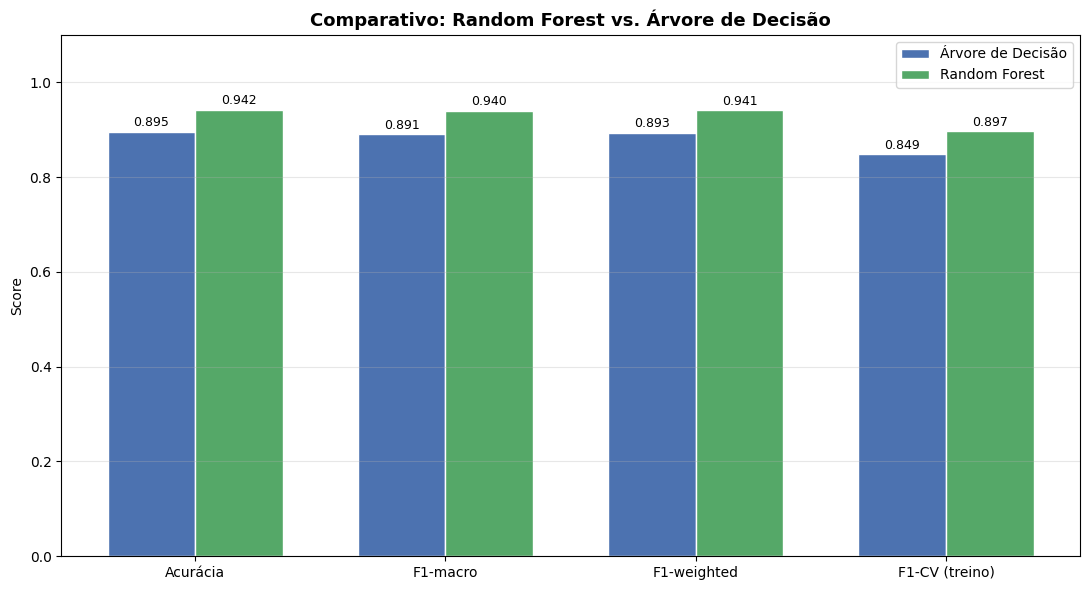

In [22]:
# Gráfico comparativo
metricas  = ['Acurácia', 'F1-macro', 'F1-weighted', 'F1-CV (treino)']
vals_dt   = [df_res.loc['Árvore de Decisão', m] for m in metricas]
vals_rf   = [df_res.loc['Random Forest',     m] for m in metricas]

x     = np.arange(len(metricas))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
bars1 = ax.bar(x - width/2, vals_dt, width, label='Árvore de Decisão',
               color='#4C72B0', edgecolor='white')
bars2 = ax.bar(x + width/2, vals_rf, width, label='Random Forest',
               color='#55A868', edgecolor='white')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Comparativo: Random Forest vs. Árvore de Decisão', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

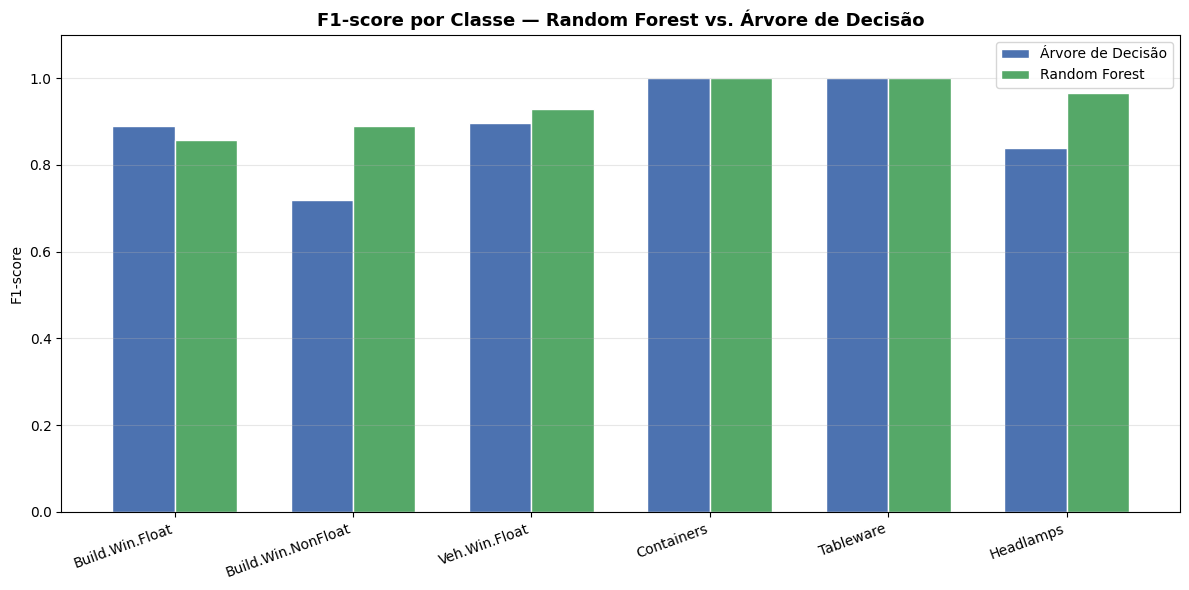


=== DIFERENÇA (RF - DT) POR CLASSE ===
   Build.Win.Float        DT=0.889  RF=0.857  Δ=-0.032 📉
   Build.Win.NonFloat     DT=0.720  RF=0.889  Δ=+0.169 📈
   Veh.Win.Float          DT=0.897  RF=0.929  Δ=+0.032 📈
   Containers             DT=1.000  RF=1.000  Δ=+0.000 ➡️
   Tableware              DT=1.000  RF=1.000  Δ=+0.000 ➡️
   Headlamps              DT=0.839  RF=0.966  Δ=+0.127 📈


In [23]:
# Comparativo de F1 por classe
from sklearn.metrics import f1_score as f1

f1_dt_classes = f1(y_test, y_pred_dt, average=None, labels=classes)
f1_rf_classes = f1(y_test, y_pred,    average=None, labels=classes)

x     = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width/2, f1_dt_classes, width, label='Árvore de Decisão',
       color='#4C72B0', edgecolor='white')
ax.bar(x + width/2, f1_rf_classes, width, label='Random Forest',
       color='#55A868', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=20, ha='right')
ax.set_ylim(0, 1.1)
ax.set_ylabel('F1-score')
ax.set_title('F1-score por Classe — Random Forest vs. Árvore de Decisão',
             fontsize=13, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('\n=== DIFERENÇA (RF - DT) POR CLASSE ===')
for lbl, dt_val, rf_val in zip(labels, f1_dt_classes, f1_rf_classes):
    diff   = rf_val - dt_val
    emoji  = '📈' if diff > 0 else ('📉' if diff < 0 else '➡️')
    print(f'   {lbl:<22} DT={dt_val:.3f}  RF={rf_val:.3f}  Δ={diff:+.3f} {emoji}')

In [24]:
print('=' * 55)
print('          RESUMO FINAL — RANDOM FOREST')
print('=' * 55)
print(f'  Número de árvores:    {best_rf.n_estimators}')
print(f'  Profundidade máxima:  {best_rf.max_depth}')
print(f'  Max features/split:   {best_rf.max_features}')
print(f'  Min amostras/folha:   {best_rf.min_samples_leaf}')
print(f'  Bootstrap:            {best_rf.bootstrap}')
print(f'  F1-macro (CV):        {grid_search.best_score_:.4f}')
print(f'  F1-macro (teste):     {f1_score(y_test, y_pred, average="macro"):.4f}')
print(f'  Acurácia (teste):     {accuracy_score(y_test, y_pred):.4f}')
print()
melhoria = f1_score(y_test, y_pred, average='macro') - f1_score(y_test, y_pred_dt, average='macro')
print(f'  Melhoria vs. Árvore:  {melhoria:+.4f} (F1-macro)')
print('=' * 55)

          RESUMO FINAL — RANDOM FOREST
  Número de árvores:    100
  Profundidade máxima:  None
  Max features/split:   sqrt
  Min amostras/folha:   1
  Bootstrap:            True
  F1-macro (CV):        0.8969
  F1-macro (teste):     0.9400
  Acurácia (teste):     0.9419

  Melhoria vs. Árvore:  +0.0493 (F1-macro)


---
## ✅ Conclusão do Pipeline

| Etapa | Ação | Justificativa |
|---|---|---|
| 1 | Remoção do ID | Evita overfitting trivial |
| 2 | Verificação de duplicatas | Garante integridade dos dados |
| 3 | Outliers (Z-score > 3.5) | Reduz ruído nas árvores individuais |
| 4 | SMOTE | Equilibra as 6 classes desiguais |
| 5 | Engenharia de features | Flags binárias + razões químicas |
| 6 | Divisão estratificada | Mantém proporção de classes |
| 7 | Análise de n_estimators | Evita buscar em grade um parâmetro monotônico |
| 8 | GridSearchCV + StratifiedKFold | Otimização robusta com F1-macro |
| 9 | OOB Score | Estimativa gratuita de generalização |
| 10 | Comparativo DT vs. RF | Quantifica o ganho do ensemble |

### Por que o Random Forest supera a Árvore de Decisão?

- **Bagging:** cada árvore treina em uma amostra diferente → reduz variância
- **Feature sampling:** splits em subconjuntos aleatórios de features → diversidade entre árvores
- **Votação majoritária:** erros individuais se cancelam → resultado mais estável
- **Robustez natural a splits espúrios:** um split espúrio em uma árvore é compensado pelas demais

---
*Dataset: German, B. (1987). Glass Identification. UCI Machine Learning Repository. https://doi.org/10.24432/C5WW2P*